In [6]:
# create the figure for the introduction 
# that hopefully looks really good and explains the gist of the paper

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 600
# # fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25

# new style
preamble = r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
"""

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "figure.titlesize": 7,

    "figure.dpi": 300,
    "savefig.bbox": None,

        # Settings for PDF export through LaTeX:
    "pgf.texsystem": "pdflatex",
    "pgf.rcfonts": False,
    "pgf.preamble": preamble,
})

fig_width = 170 / 25.4  # 6.693 inches

/Library/TeX/texbin/latex


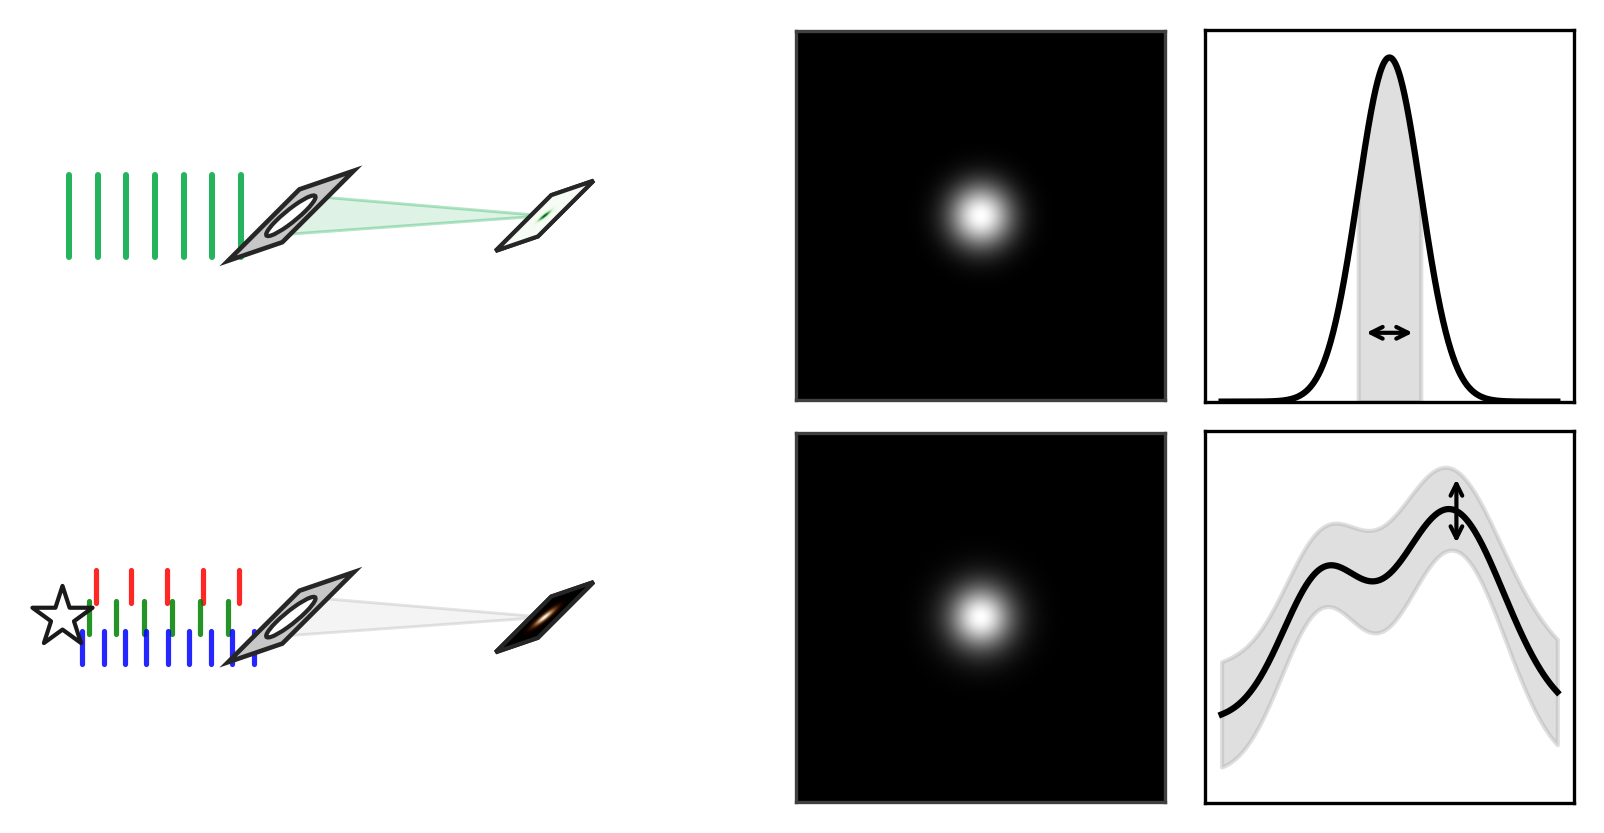

In [7]:
import matplotlib.pyplot as plt

from matplotlib.patches import Polygon, Circle
from matplotlib.transforms import Affine2D


# ============================================================
# USER INPUT: REPLACE THESE WITH YOUR OWN PSF ARRAYS
# ============================================================

# Everything below assumes square 2D arrays of the same size.
#
# psf_mono = ...
# psf_r    = ...
# psf_g    = ...
# psf_b    = ...


# ------------------------------------------------------------
# Temporary demonstration PSFs so that this script runs as-is.
# Delete this section once you insert your actual arrays.
# ------------------------------------------------------------

def demo_psf(width, n=256):
    x = np.linspace(-1, 1, n)
    xx, yy = np.meshgrid(x, x)
    rr2 = xx**2 + yy**2
    return np.exp(-rr2 / (2 * width**2))


psf_mono = demo_psf(0.12)

# Wider PSF at longer wavelength
psf_b = demo_psf(0.095)
psf_g = demo_psf(0.120)
psf_r = demo_psf(0.150)


# ============================================================
# DISPLAY VERSIONS OF THE PSFs
# ============================================================

# Monochromatic PSF
mono_display = psf_mono / np.nanmax(psf_mono)

# RGB polychromatic visualisation.
#
# IMPORTANT:
# np.stack(..., axis=-1) gives shape (Ny, Nx, 3), which imshow
# interprets directly as RGB.
rgb = np.stack([psf_r, psf_g, psf_b], axis=-1)

# One common normalisation preserves the relative brightness
# between the three wavelength components.
rgb /= np.nanmax(rgb)
rgb = np.clip(rgb, 0, 1)

# Optional display gamma to make faint PSF structure visible.
# Set gamma = 1.0 for a linear display.
gamma = 0.45
rgb_display = rgb**gamma

# What the wavelength-insensitive detector actually sees.
psf_poly = psf_r + psf_g + psf_b
poly_display = psf_poly / np.nanmax(psf_poly)


# ============================================================
# FIGURE LAYOUT
# ============================================================

fig = plt.figure(figsize=(fig_width, fig_width/2))

gs = fig.add_gridspec(
    2, 3,
    width_ratios=[2, 1, 1],
    height_ratios=[1, 1],
    wspace=0.08,
    hspace=0.08,
)

ax_opt_mono = fig.add_subplot(gs[0, 0])
ax_det_mono = fig.add_subplot(gs[0, 1])
ax_inf_mono = fig.add_subplot(gs[0, 2])

ax_opt_poly = fig.add_subplot(gs[1, 0])
ax_det_poly = fig.add_subplot(gs[1, 1])
ax_inf_poly = fig.add_subplot(gs[1, 2])


# ============================================================
# GENERAL OPTICS-CARTOON GEOMETRY
# ============================================================

for ax in [ax_opt_mono, ax_opt_poly]:
    ax.set_xlim(0, 10)
    ax.set_ylim(-2.6, 2.6)
    ax.set_aspect("equal")
    ax.axis("off")


# ------------------------------------------------------------
# The aperture plane
# ------------------------------------------------------------
#
# Define a square in LOCAL coordinates:
#
#       (-1,+1) ---------- (+1,+1)
#          |                  |
#          |       (0,0)      |
#          |                  |
#       (-1,-1) ---------- (+1,-1)
#
# and put a unit circle inside it.
#
# We then map that entire plane into the figure using a single
# affine transformation.
#
# Because affine maps preserve parallel lines:
#    square -> parallelogram
#
# and:
#    circle -> ellipse
#
# So the perspective of the hole and plate is necessarily
# geometrically consistent.
# ------------------------------------------------------------

# Apparent basis vectors of the projected aperture plane.
#
# The first vector is the projected local horizontal direction.
# The second is the projected local vertical direction.
#
# Change these four numbers to adjust the viewing angle.
plane_ex = np.array([0.38, 0.13])
plane_ey = np.array([0.5, 0.5])

aperture_center = np.array([3.65, 0.0])
focus_center    = np.array([7.20, 0.0])

# Aperture radius in local square coordinates.
# radius = 0.55 means the hole diameter is 55% of the plate width.
hole_radius = 0.55


def plane_transform(center, scale=1.0):
    """
    Affine transformation from the local square coordinates
    into the 2D figure coordinates.

    SAME LINEAR TRANSFORMATION is used for aperture and
    focal-plane screen, guaranteeing identical orientation.
    """

    ex = scale * plane_ex
    ey = scale * plane_ey

    # Matplotlib affine convention:
    #
    # x' = a*x + c*y + e
    # y' = b*x + d*y + f

    return Affine2D.from_values(
        ex[0], ex[1],
        ey[0], ey[1],
        center[0], center[1],
    )


def transform_points(transform, points):
    """Convenience function for transforming local coordinates."""
    return transform.transform(np.asarray(points))


# ============================================================
# DRAW THE APERTURE
# ============================================================

def draw_aperture(ax):

    T = plane_transform(aperture_center)

    # Original square before projection
    square_local = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    # Project the square.
    square_projected = transform_points(T, square_local)

    plate = Polygon(
        square_projected,
        closed=True,
        facecolor="0.78",
        edgecolor="0.15",
        linewidth=1.1,
        zorder=4,
    )

    ax.add_patch(plate)

    # IMPORTANT:
    # This is a genuine CIRCLE in the original square plane.
    # The SAME transformation which turns the square into the
    # parallelogram turns this circle into the correct ellipse.
    hole = Circle(
        (0, 0),
        radius=hole_radius,
        facecolor="white",
        edgecolor="0.15",
        linewidth=1.0,
        transform=T + ax.transData,
        zorder=5,
    )

    ax.add_patch(hole)


# ============================================================
# CONVERGING LIGHT CONE
# ============================================================

def draw_converging_cone(ax, color, alpha=0.14):

    T = plane_transform(aperture_center)

    # Opposite points on the original circular aperture.
    # These are transformed using the SAME aperture transform.
    p_top, p_bottom = transform_points(
        T,
        [
            [0,  hole_radius],
            [0, -hole_radius],
        ],
    )

    cone = Polygon(
        [p_top, focus_center, p_bottom],
        closed=True,
        facecolor=color,
        edgecolor="none",
        alpha=alpha,
        zorder=1,
    )

    ax.add_patch(cone)

    # Very subtle boundaries
    ax.plot(
        [p_top[0], focus_center[0]],
        [p_top[1], focus_center[1]],
        color=color,
        alpha=0.30,
        linewidth=0.7,
        zorder=2,
    )

    ax.plot(
        [p_bottom[0], focus_center[0]],
        [p_bottom[1], focus_center[1]],
        color=color,
        alpha=0.30,
        linewidth=0.7,
        zorder=2,
    )


# ============================================================
# FOCAL-PLANE SCREEN + PSF
# ============================================================

def draw_focal_screen(ax, image, cmap=None):

    # The focal plane has EXACTLY the same orientation as the
    # aperture plane.
    #
    # Changing screen_scale changes only its physical/display
    # size, not its perspective.
    screen_scale = 0.78

    T = plane_transform(
        focus_center,
        scale=screen_scale,
    )

    # White plate behind the image.
    screen_local = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    screen_projected = transform_points(T, screen_local)

    screen = Polygon(
        screen_projected,
        closed=True,
        facecolor="white",
        edgecolor="0.15",
        linewidth=1.0,
        zorder=6,
    )

    ax.add_patch(screen)

    # The PSF itself occupies the exact same original square,
    # so after transformation its four edges coincide with the
    # focal-plane screen.
    ax.imshow(
        image,
        extent=[-1, 1, -1, 1],
        origin="lower",
        cmap=cmap,
        interpolation="bilinear",
        transform=T + ax.transData,
        zorder=7,
        clip_on=True,
    )

    # Redraw the boundary over the image.
    boundary = Polygon(
        screen_projected,
        closed=True,
        facecolor="none",
        edgecolor="0.15",
        linewidth=1.0,
        zorder=8,
    )

    ax.add_patch(boundary)


# ============================================================
# WAVEFRONT TRAINS
# ============================================================

def draw_wavefront_train(
    ax,
    x_start,
    x_stop,
    y_center,
    spacing,
    height,
    color,
    linewidth=1.3,
    alpha=0.85,
):
    """
    Draw repeated straight wavefront markers:

           |   |   |   |   |

    'spacing' is the schematic wavelength.
    No sinusoids are used.
    """

    xs = np.arange(x_start, x_stop, spacing)

    for x in xs:
        ax.plot(
            [x, x],
            [
                y_center - height / 2,
                y_center + height / 2,
            ],
            color=color,
            linewidth=linewidth,
            alpha=alpha,
            solid_capstyle="round",
            zorder=3,
        )


# ============================================================
# MONOCHROMATIC OPTICAL CARTOON
# ============================================================

draw_converging_cone(
    ax_opt_mono,
    color=(0.0, 0.65, 0.25),
    alpha=0.13,
)

draw_aperture(ax_opt_mono)

draw_wavefront_train(
    ax_opt_mono,
    x_start=0.55,
    x_stop=3.15,
    y_center=0.0,
    spacing=0.40,
    height=1.15,
    color=(0.0, 0.65, 0.25),
    linewidth=1.45,
)

draw_focal_screen(
    ax_opt_mono,
    mono_display,
    cmap="Greens",
)


# ============================================================
# POLYCHROMATIC OPTICAL CARTOON
# ============================================================

# White converging region
draw_converging_cone(
    ax_opt_poly,
    color="0.65",
    alpha=0.12,
)

draw_aperture(ax_opt_poly)


# ------------------------------------------------------------
# White star source
# ------------------------------------------------------------

star_x = 0.45
star_y = 0.0

ax_opt_poly.scatter(
    star_x,
    star_y,
    marker="*",
    s=230,
    facecolor="white",
    edgecolor="0.10",
    linewidth=1.0,
    zorder=6,
    clip_on=False,
)



# ------------------------------------------------------------
# Red, green, blue wavefront trains
#
# Same geometrical object as the monochromatic case.
#
# Different:
#   - vertical starting position
#   - first x position
#   - spacing ("wavelength")
#
# Red has the largest period.
# Blue has the smallest.
# ------------------------------------------------------------

draw_wavefront_train(
    ax_opt_poly,
    x_start=0.92,
    x_stop=3.15,
    y_center=0.43,
    spacing=0.50,
    height=0.46,
    color="red",
    linewidth=1.25,
)

draw_wavefront_train(
    ax_opt_poly,
    x_start=0.82,
    x_stop=3.15,
    y_center=0.00,
    spacing=0.39,
    height=0.46,
    color="green",
    linewidth=1.25,
)

draw_wavefront_train(
    ax_opt_poly,
    x_start=0.73,
    x_stop=3.15,
    y_center=-0.43,
    spacing=0.30,
    height=0.46,
    color="blue",
    linewidth=1.25,
)


draw_focal_screen(
    ax_opt_poly,
    rgb_display,
)


# ============================================================
# FACE-ON DETECTOR PSFs
# ============================================================

def format_detector_axis(ax):

    ax.set_aspect("equal")

    ax.set_xticks([])
    ax.set_yticks([])

    # Keep a thin box because this visually reads as a detector.
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("0.25")


ax_det_mono.imshow(
    mono_display,
    origin="lower",
    cmap="gray",
    interpolation="bilinear",
)

format_detector_axis(ax_det_mono)


ax_det_poly.imshow(
    poly_display,
    origin="lower",
    cmap="gray",
    interpolation="bilinear",
)

format_detector_axis(ax_det_poly)


# ============================================================
# MONOCHROMATIC INFERENCE PANEL
# ============================================================

lam = np.linspace(-4, 4, 500)

lam0 = 0.0
sigma_lam = 0.75

likelihood = np.exp(
    -0.5 * ((lam - lam0) / sigma_lam)**2
)


ax_inf_mono.plot(
    lam,
    likelihood,
    color="black",
    linewidth=1.5,
)


# Shade the +/- 1 sigma Fisher interval.
inside = np.abs(lam - lam0) <= sigma_lam

ax_inf_mono.fill_between(
    lam[inside],
    0,
    likelihood[inside],
    color="0.65",
    alpha=0.35,
)


# Horizontal uncertainty marker.
y_unc = 0.20

ax_inf_mono.annotate(
    "",
    xy=(lam0 + sigma_lam, y_unc),
    xytext=(lam0 - sigma_lam, y_unc),
    arrowprops=dict(
        arrowstyle="<->",
        color="black",
        linewidth=1.0,
    ),
)


# ============================================================
# POLYCHROMATIC SPECTRUM PANEL
# ============================================================

# Placeholder spectrum.
# Replace this entire section with your preferred spectrum.

wave = np.linspace(0, 1, 500)

spectrum = (
    0.45
    + 0.20 * np.exp(-0.5 * ((wave - 0.30) / 0.12)**2)
    + 0.30 * np.exp(-0.5 * ((wave - 0.68) / 0.16)**2)
)

# Placeholder uncertainty band.
sigma_theta = (
    0.055
    + 0.020 * np.cos(2 * np.pi * wave)**2
)


ax_inf_poly.plot(
    wave,
    spectrum,
    color="black",
    linewidth=1.5,
)

ax_inf_poly.fill_between(
    wave,
    spectrum - sigma_theta,
    spectrum + sigma_theta,
    color="0.65",
    alpha=0.35,
)


# A small representative uncertainty marker.
#
# You said you'll likely handle this panel yourself, so this is
# deliberately minimal.
x_unc = 0.70

i_unc = np.argmin(np.abs(wave - x_unc))

ax_inf_poly.annotate(
    "",
    xy=(
        wave[i_unc],
        spectrum[i_unc] + sigma_theta[i_unc],
    ),
    xytext=(
        wave[i_unc],
        spectrum[i_unc] - sigma_theta[i_unc],
    ),
    arrowprops=dict(
        arrowstyle="<->",
        color="black",
        linewidth=1.0,
    ),
)


# ============================================================
# REMOVE TEXT/TICK LABELS FROM INFERENCE PANELS FOR NOW
# ============================================================

for ax in [ax_inf_mono, ax_inf_poly]:

    ax.tick_params(
        bottom=False,
        left=False,
        labelbottom=False,
        labelleft=False,
    )

#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)

#     ax.spines["bottom"].set_linewidth(0.8)
#     ax.spines["left"].set_linewidth(0.8)


# Give inference plots a little breathing room.
ax_inf_mono.set_ylim(0, 1.08)

ymin = np.min(spectrum - sigma_theta)
ymax = np.max(spectrum + sigma_theta)
pad = 0.12 * (ymax - ymin)

ax_inf_poly.set_ylim(
    ymin - pad,
    ymax + pad,
)

# fig.subplots_adjust(
#     left=0.0,
#     right=1.0,
#     bottom=0.0,
#     top=1.0,
#     # wspace=0.08,
#     # hspace=0.08,
# )

plt.show()

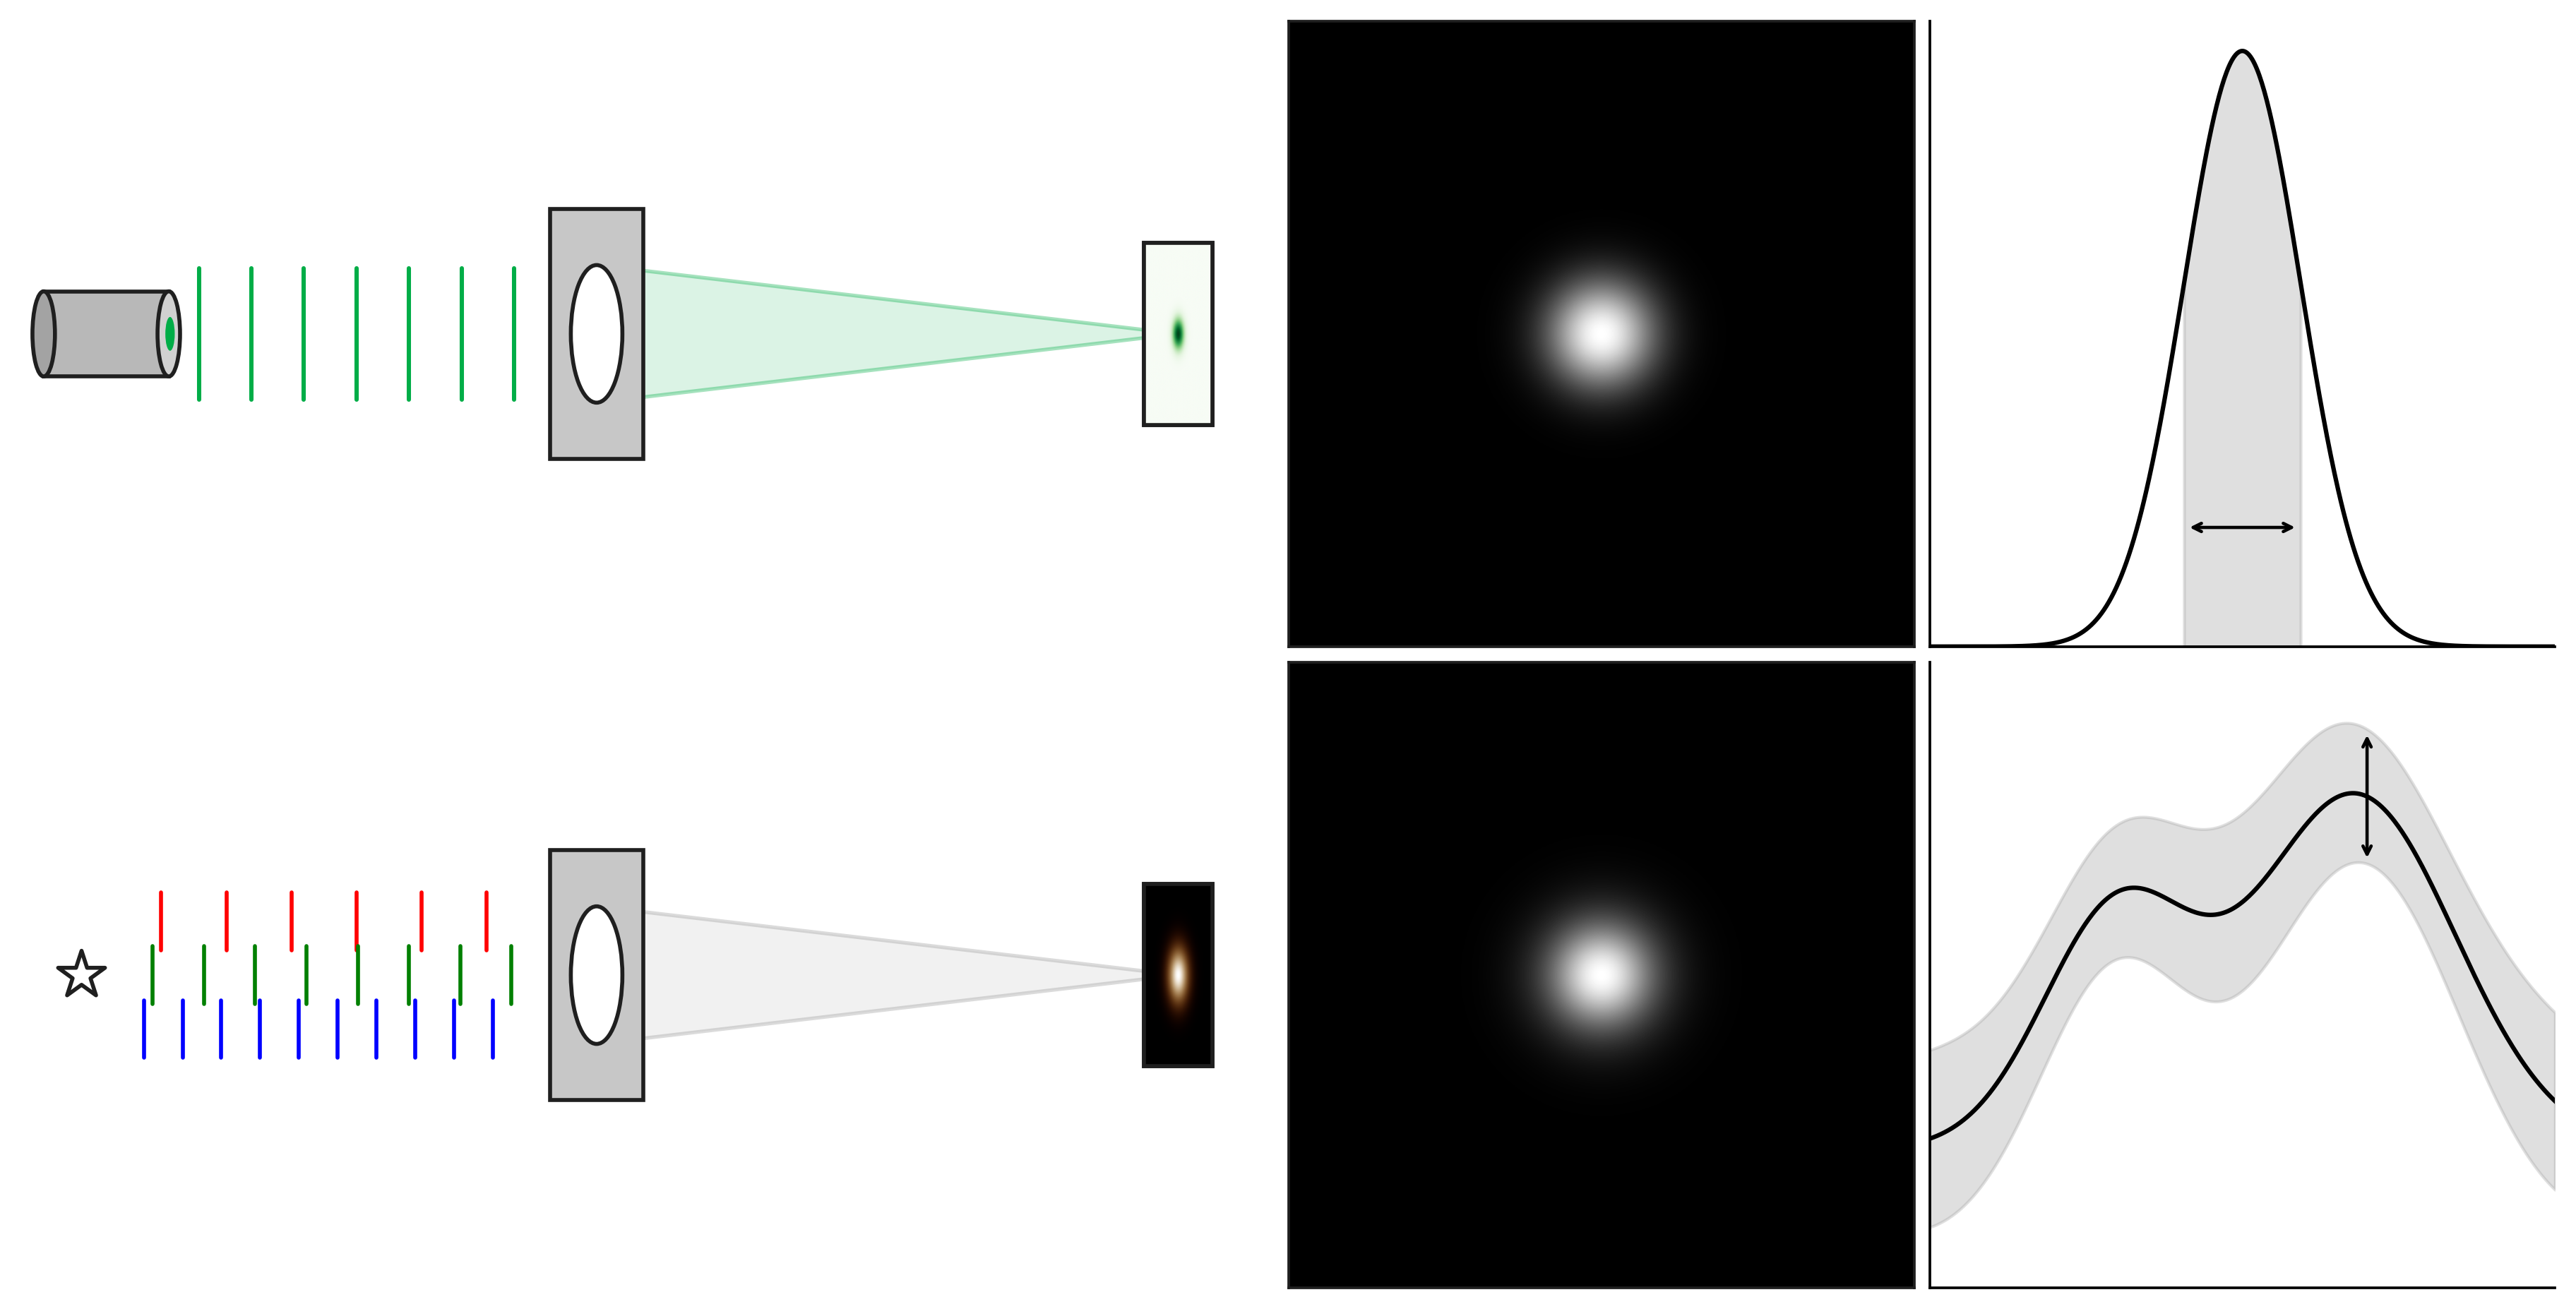

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Polygon, Circle, Rectangle, Ellipse
from matplotlib.transforms import Affine2D


# ============================================================
# FIGURE SIZE
# ============================================================
#
# IMPORTANT:
# For the geometry below to fit perfectly:
#
#   left half  = optical train, aspect ratio ~2:1
#   right half = two square panels
#
# the whole figure should have width / height ~= 2.
#
# Change FIG_W to whatever your paper requires, and preferably
# keep FIG_H = FIG_W / 2.
# ============================================================

FIG_W = 12.0
FIG_H = 6.0


# ============================================================
# YOUR PSFs
# ============================================================
#
# Replace these demonstration PSFs with your own arrays:
#
# psf_mono = ...
# psf_r    = ...
# psf_g    = ...
# psf_b    = ...
#
# Each should be a square 2D numpy array.
# ============================================================

def demo_psf(width, n=256):
    x = np.linspace(-1, 1, n)
    xx, yy = np.meshgrid(x, x)
    rr2 = xx**2 + yy**2
    return np.exp(-rr2 / (2 * width**2))


psf_mono = demo_psf(0.12)

psf_b = demo_psf(0.095)
psf_g = demo_psf(0.120)
psf_r = demo_psf(0.150)


# ============================================================
# PSF DISPLAY ARRAYS
# ============================================================

mono_display = psf_mono / np.nanmax(psf_mono)

# RGB array:
# shape = (Ny, Nx, 3)
#
# imshow directly interprets the last dimension as RGB.
rgb = np.stack(
    [psf_r, psf_g, psf_b],
    axis=-1,
)

# ONE common normalisation, so relative channel brightness
# is preserved.
rgb /= np.nanmax(rgb)
rgb = np.clip(rgb, 0, 1)

# Display gamma just makes faint structure easier to see.
# Set to 1.0 if you want a strictly linear RGB display.
gamma = 0.45
rgb_display = rgb**gamma

# Wavelength-insensitive detector:
psf_poly = psf_r + psf_g + psf_b
poly_display = psf_poly / np.nanmax(psf_poly)


# ============================================================
# LAYOUT
# ============================================================
#
# Width ratios:
#
#       2        1        1
#   [ optics ][ PSF ][ inference ]
#
# Therefore:
#
#   optics = exactly left half
#   PSF + inference = exactly right half
#
# constrained_layout handles spacing without modifying figsize.
# ============================================================

fig, axs = plt.subplots(
    2,
    3,
    figsize=(FIG_W, FIG_H),
    gridspec_kw={
        "width_ratios": [2, 1, 1],
        "height_ratios": [1, 1],
    },
    constrained_layout=True,
)

ax_opt_mono, ax_det_mono, ax_inf_mono = axs[0]
ax_opt_poly, ax_det_poly, ax_inf_poly = axs[1]


# Small controlled gaps.
#
# These are handled by constrained_layout rather than
# subplots_adjust.
fig.get_layout_engine().set(
    w_pad=0.01,
    h_pad=0.01,
    wspace=0.015,
    hspace=0.025,
)


# ============================================================
# AXES GEOMETRY
# ============================================================

# Optical panels are twice as wide as they are high.
for ax in [ax_opt_mono, ax_opt_poly]:

    ax.set_box_aspect(0.5)

    ax.set_xlim(0, 10)
    ax.set_ylim(-2.5, 2.5)

    ax.axis("off")


# Every panel on the right is physically square.
for ax in [
    ax_det_mono,
    ax_inf_mono,
    ax_det_poly,
    ax_inf_poly,
]:
    ax.set_box_aspect(1)


# ============================================================
# COMMON DRAWING PARAMETERS
# ============================================================

green = (0.0, 0.68, 0.28)

outline = "0.12"

LW_MAIN = 1.35
LW_LIGHT = 1.25


# ============================================================
# OPTICAL GEOMETRY
# ============================================================
#
# Optical train fills almost the full x=0...10 range.
#
#    source      waves      aperture             focal plane
#      |           |           |                      |
#      0           1          4.6                    9.3
#
# ============================================================

aperture_center = np.array([4.60, 0.0])
focus_center = np.array([9.25, 0.0])

hole_radius = 0.55


# ============================================================
# PHYSICAL APERTURE PROJECTION
# ============================================================
#
# Start with a literal square in 3D, with a literal inscribed
# circle.
#
# Rotate the plane about its VERTICAL axis by tilt_deg.
#
# Under orthographic projection:
#
#     x -> x cos(tilt)
#     y -> y
#
# Therefore:
#
#     square -> vertically aligned foreshortened rectangle
#     circle -> vertically aligned ellipse
#
# A rectangle is of course a parallelogram; importantly,
# there is no arbitrary shearing or mismatched ellipse.
#
# The exact SAME transform is used for the focal plane.
# ============================================================

tilt_deg = 68.0

foreshorten = np.cos(
    np.deg2rad(tilt_deg)
)


def plane_transform(center, scale=1.0):

    return (
        Affine2D()
        .scale(
            scale * foreshorten,
            scale,
        )
        .translate(
            center[0],
            center[1],
        )
    )


# ============================================================
# APERTURE
# ============================================================

def draw_aperture(ax):

    T = plane_transform(
        aperture_center,
        scale=1.0,
    )

    # Literal square in aperture-plane coordinates.
    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    square_projected = T.transform(square)

    plate = Polygon(
        square_projected,
        closed=True,
        facecolor="0.78",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=5,
    )

    ax.add_patch(plate)

    # Literal circle in the same original square plane.
    #
    # The same affine projection automatically turns it
    # into the physically consistent ellipse.
    hole = Circle(
        (0, 0),
        radius=hole_radius,
        facecolor="white",
        edgecolor=outline,
        linewidth=LW_MAIN,
        transform=T + ax.transData,
        zorder=6,
    )

    ax.add_patch(hole)


# ============================================================
# CONVERGING CONE
# ============================================================

def draw_cone(
    ax,
    color,
    alpha=0.13,
):

    T = plane_transform(aperture_center)

    # Top and bottom of the circular opening before projection.
    p_top, p_bottom = T.transform([
        [0,  hole_radius],
        [0, -hole_radius],
    ])

    cone = Polygon(
        [
            p_top,
            focus_center,
            p_bottom,
        ],
        closed=True,
        facecolor=color,
        edgecolor="none",
        alpha=alpha,
        zorder=1,
    )

    ax.add_patch(cone)

    # Cone boundaries.
    ax.plot(
        [p_top[0], focus_center[0]],
        [p_top[1], focus_center[1]],
        color=color,
        alpha=0.35,
        linewidth=LW_LIGHT,
        zorder=2,
    )

    ax.plot(
        [p_bottom[0], focus_center[0]],
        [p_bottom[1], focus_center[1]],
        color=color,
        alpha=0.35,
        linewidth=LW_LIGHT,
        zorder=2,
    )


# ============================================================
# FOCAL PLANE + PSF
# ============================================================

def draw_focal_screen(
    ax,
    image,
    cmap=None,
):

    screen_scale = 0.73

    # EXACTLY the same orientation as the aperture.
    T = plane_transform(
        focus_center,
        scale=screen_scale,
    )

    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    square_projected = T.transform(square)

    # White screen underneath.
    screen = Polygon(
        square_projected,
        closed=True,
        facecolor="white",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=7,
    )

    ax.add_patch(screen)

    # PSF image.
    #
    # aspect="auto" is deliberate:
    # the physical geometry is supplied by T, so imshow should
    # NOT try to impose another axes-level equal-aspect rule.
    ax.imshow(
        image,
        extent=[-1, 1, -1, 1],
        origin="lower",
        cmap=cmap,
        interpolation="bilinear",
        transform=T + ax.transData,
        aspect="auto",
        zorder=8,
        clip_on=True,
    )

    # Re-draw the screen boundary over the PSF.
    boundary = Polygon(
        square_projected,
        closed=True,
        facecolor="none",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=9,
    )

    ax.add_patch(boundary)


# ============================================================
# WAVEFRONTS
# ============================================================
#
# Simple straight wavefront markers:
#
#       |   |   |   |   |
#
# Red / green / blue use the exact same type of object;
# only their spacing and vertical position differ.
# ============================================================

def draw_wavefronts(
    ax,
    x_start,
    x_stop,
    y,
    spacing,
    height,
    color,
    linewidth=1.45,
):

    xs = np.arange(
        x_start,
        x_stop,
        spacing,
    )

    for x in xs:

        ax.plot(
            [x, x],
            [
                y - height / 2,
                y + height / 2,
            ],
            color=color,
            linewidth=linewidth,
            solid_capstyle="round",
            zorder=3,
        )


# ============================================================
# LASER
# ============================================================
#
# Very simple cylindrical laser:
#
#     ellipse + rectangle + ellipse
#
# with a small green emitter on the front.
# ============================================================

def draw_laser(
    ax,
    x=0.18,
    y=0.0,
):

    width = 1.00
    height = 0.68

    end_width = 0.18


    # Body
    body = Rectangle(
        (x, y - height / 2),
        width,
        height,
        facecolor="0.72",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=5,
    )

    ax.add_patch(body)


    # Rear curved end
    rear = Ellipse(
        (x, y),
        width=end_width,
        height=height,
        facecolor="0.64",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=6,
    )

    ax.add_patch(rear)


    # Front curved end
    front = Ellipse(
        (x + width, y),
        width=end_width,
        height=height,
        facecolor="0.82",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=6,
    )

    ax.add_patch(front)


    # Green emitting aperture
    emitter = Ellipse(
        (
            x + width + 0.01,
            y,
        ),
        width=0.075,
        height=0.27,
        facecolor=green,
        edgecolor="none",
        zorder=7,
    )

    ax.add_patch(emitter)


# ============================================================
# MONOCHROMATIC OPTICAL ROW
# ============================================================

draw_laser(
    ax_opt_mono,
    x=0.18,
    y=0.0,
)


draw_wavefronts(
    ax_opt_mono,
    x_start=1.42,
    x_stop=4.05,
    y=0.0,
    spacing=0.42,
    height=1.05,
    color=green,
)


draw_cone(
    ax_opt_mono,
    color=green,
    alpha=0.14,
)


draw_aperture(
    ax_opt_mono
)


draw_focal_screen(
    ax_opt_mono,
    mono_display,
    cmap="Greens",
)


# ============================================================
# POLYCHROMATIC OPTICAL ROW
# ============================================================

# White star source.
ax_opt_poly.scatter(
    0.48,
    0.0,
    marker="*",
    s=280,
    facecolor="white",
    edgecolor=outline,
    linewidth=LW_MAIN,
    zorder=8,
)


# RED
draw_wavefronts(
    ax_opt_poly,
    x_start=1.12,
    x_stop=4.05,
    y=0.43,
    spacing=0.52,
    height=0.46,
    color="red",
    linewidth=1.35,
)


# GREEN
draw_wavefronts(
    ax_opt_poly,
    x_start=1.05,
    x_stop=4.05,
    y=0.00,
    spacing=0.41,
    height=0.46,
    color="green",
    linewidth=1.35,
)


# BLUE
draw_wavefronts(
    ax_opt_poly,
    x_start=0.98,
    x_stop=4.05,
    y=-0.43,
    spacing=0.31,
    height=0.46,
    color="blue",
    linewidth=1.35,
)


# White/grey combined converging region.
draw_cone(
    ax_opt_poly,
    color="0.60",
    alpha=0.13,
)


draw_aperture(
    ax_opt_poly
)


draw_focal_screen(
    ax_opt_poly,
    rgb_display,
)


# ============================================================
# FACE-ON DETECTOR PSFs
# ============================================================
#
# Since the axes themselves are physically square, using
# aspect="auto" here does NOT distort a square image.
#
# It simply prevents imshow from resizing the axes.
# ============================================================

ax_det_mono.imshow(
    mono_display,
    origin="lower",
    cmap="gray",
    interpolation="bilinear",
    aspect="auto",
)


ax_det_poly.imshow(
    poly_display,
    origin="lower",
    cmap="gray",
    interpolation="bilinear",
    aspect="auto",
)


for ax in [
    ax_det_mono,
    ax_det_poly,
]:

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)
        spine.set_color(outline)


# ============================================================
# MONOCHROMATIC INFERENCE PANEL
# ============================================================

lam = np.linspace(
    -4,
    4,
    500,
)

lam0 = 0.0
sigma_lam = 0.75


likelihood = np.exp(
    -0.5
    * ((lam - lam0) / sigma_lam)**2
)


ax_inf_mono.plot(
    lam,
    likelihood,
    color="black",
    linewidth=1.5,
)


inside = (
    np.abs(lam - lam0)
    <= sigma_lam
)


ax_inf_mono.fill_between(
    lam[inside],
    0,
    likelihood[inside],
    color="0.65",
    alpha=0.35,
)


# Horizontal uncertainty marker.
y_unc = 0.20

ax_inf_mono.annotate(
    "",
    xy=(
        lam0 + sigma_lam,
        y_unc,
    ),
    xytext=(
        lam0 - sigma_lam,
        y_unc,
    ),
    arrowprops=dict(
        arrowstyle="<->",
        color="black",
        linewidth=1.1,
    ),
)


ax_inf_mono.set_xlim(
    lam.min(),
    lam.max(),
)

ax_inf_mono.set_ylim(
    0,
    1.05,
)


# ============================================================
# POLYCHROMATIC INFERENCE PANEL
# ============================================================
#
# Deliberately simple placeholder.
#
# Replace this with your actual preferred spectrum and
# uncertainty region.
# ============================================================

wave = np.linspace(
    0,
    1,
    500,
)


spectrum = (
    0.45
    + 0.20
    * np.exp(
        -0.5
        * ((wave - 0.30) / 0.12)**2
    )
    + 0.30
    * np.exp(
        -0.5
        * ((wave - 0.68) / 0.16)**2
    )
)


sigma_theta = (
    0.055
    + 0.020
    * np.cos(
        2 * np.pi * wave
    )**2
)


ax_inf_poly.plot(
    wave,
    spectrum,
    color="black",
    linewidth=1.5,
)


ax_inf_poly.fill_between(
    wave,
    spectrum - sigma_theta,
    spectrum + sigma_theta,
    color="0.65",
    alpha=0.35,
)


# Representative vertical uncertainty marker.
x_unc = 0.70

i_unc = np.argmin(
    np.abs(
        wave - x_unc
    )
)


ax_inf_poly.annotate(
    "",
    xy=(
        wave[i_unc],
        spectrum[i_unc] + sigma_theta[i_unc],
    ),
    xytext=(
        wave[i_unc],
        spectrum[i_unc] - sigma_theta[i_unc],
    ),
    arrowprops=dict(
        arrowstyle="<->",
        color="black",
        linewidth=1.1,
    ),
)


ax_inf_poly.set_xlim(
    wave.min(),
    wave.max(),
)


ymin = np.min(
    spectrum - sigma_theta
)

ymax = np.max(
    spectrum + sigma_theta
)

ypad = 0.12 * (
    ymax - ymin
)

ax_inf_poly.set_ylim(
    ymin - ypad,
    ymax + ypad,
)


# ============================================================
# REMOVE ALL TEXT / TICKS FOR NOW
# ============================================================

for ax in [
    ax_inf_mono,
    ax_inf_poly,
]:

    ax.tick_params(
        bottom=False,
        left=False,
        labelbottom=False,
        labelleft=False,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["bottom"].set_linewidth(0.9)
    ax.spines["left"].set_linewidth(0.9)


# ============================================================
# SHOW / SAVE
# ============================================================

plt.show()

# For the paper:
#
# fig.savefig("spectral_information_figure.pdf")
#
# DO NOT use:
#
#     bbox_inches="tight"
#     plt.tight_layout()
#     fig.subplots_adjust(...)
#
# This preserves the exact FIG_W x FIG_H figure size.

In [9]:
# let's get some polychromatic PSFs
n_wavels = 99
d_wavel = 0.2e-6 # difference in wavelength from top and bottom
flux = 1e6
# middle wavelength
m_wavel = 1e-6
diameter = 1.0

wf_npix = 512

aperture = dlu.circular_aperture(wf_npix, diameter, 5)

psf_npix = 512

psf_pixel_scale = dlu.rad2arcsec(15e-6)/psf_npix
# psf_pixel_scale = 0.004

layers = [
    (
        'aperture',
        dl.TransmissiveLayer(aperture, True)
    )
]
optics = dl.AngularOpticalSystem(
    wf_npix,
    diameter,
    layers,
    psf_npix,
    psf_pixel_scale,
    1,
)

wavelengths = np.linspace(m_wavel - d_wavel, m_wavel + d_wavel, n_wavels)

source_m = dl.PointSource(wavelengths=np.array([m_wavel]), flux=flux)

psf_mono = optics.model(source_m) #** 0.5

wavelengths_b = wavelengths[:int(n_wavels/3)]
source_b = dl.PointSource(wavelengths=wavelengths_b, flux=flux/3)

wavelengths_g = wavelengths[int(n_wavels/3):int(-n_wavels/3)]
source_g = dl.PointSource(wavelengths=wavelengths_g, flux=flux/3)

wavelengths_r = wavelengths[int(-n_wavels/3):]
source_r = dl.PointSource(wavelengths=wavelengths_r, flux=flux/3)

psf_r = optics.model(source_r) #** 0.5
psf_g = optics.model(source_g)# ** 0.5
psf_b = optics.model(source_b)#** 0.5

# plt.imshow(aperture)
# source_r

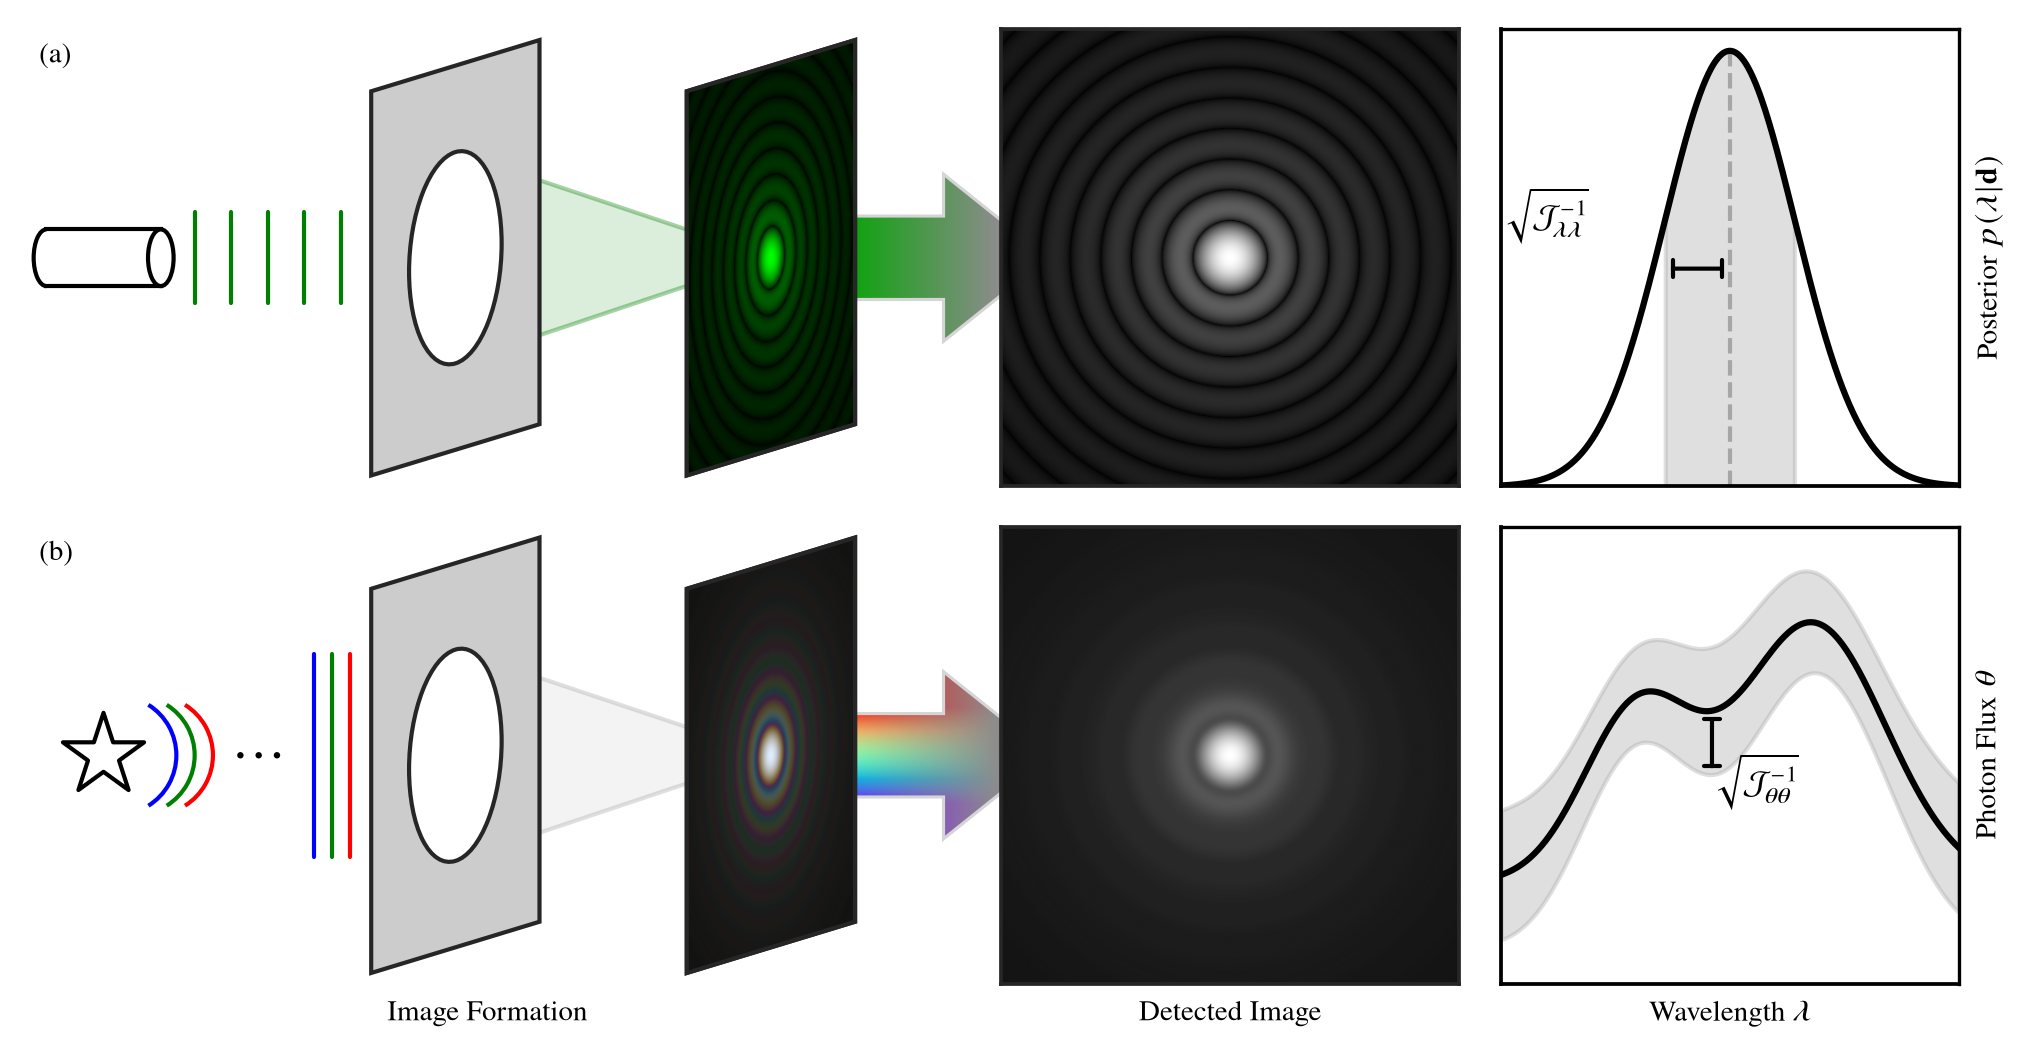

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import (
    Polygon, Circle, Rectangle, Ellipse, Arc
)
from matplotlib.transforms import Affine2D


# ============================================================
# FIGURE SIZE
# ============================================================
FIG_W = fig_width
FIG_H = fig_width/2


# ============================================================
# DEMO PSFs
# Replace these with your actual arrays:
#
# psf_mono = ...
# psf_r    = ...
# psf_g    = ...
# psf_b    = ...
#
# Each should be a square 2D numpy array.
# ============================================================

def demo_psf(width, n=256):
    x = np.linspace(-1, 1, n)
    xx, yy = np.meshgrid(x, x)
    rr2 = xx**2 + yy**2
    return np.exp(-rr2 / (2 * width**2))


# psf_mono = demo_psf(0.12)

# psf_b = demo_psf(0.095)
# psf_g = demo_psf(0.120)
# psf_r = demo_psf(0.150)


# ============================================================
# PSF DISPLAY ARRAYS
# ============================================================

# greyscale detector versions
mono_gray = psf_mono / np.nanmax(psf_mono)
poly_gray = (psf_r + psf_g + psf_b)
poly_gray = poly_gray / np.nanmax(poly_gray)

# green-on-black RGB for monochromatic focal-plane screen
mono_norm = psf_mono / np.nanmax(psf_mono)
gamma = 0.25
mono_vis = mono_norm**gamma
mono_rgb = np.dstack([
    np.zeros_like(mono_vis),
    mono_vis,
    np.zeros_like(mono_vis),
])

# RGB broadband focal-plane screen
rgb = np.dstack([psf_r, psf_g, psf_b]).astype(float)
rgb /= np.nanmax(rgb)
rgb = np.clip(rgb, 0, 1)
rgb_display = rgb**gamma


# ============================================================
# LAYOUT
# ============================================================

fig, axs = plt.subplots(
    2, 3,
    figsize=(FIG_W, FIG_H),
    gridspec_kw={
        "width_ratios": [2, 1, 1],
        "height_ratios": [1, 1],
    },
    constrained_layout=True,
)

ax_opt_mono, ax_det_mono, ax_inf_mono = axs[0]
ax_opt_poly, ax_det_poly, ax_inf_poly = axs[1]

fig.get_layout_engine().set(
    w_pad=0.01,
    h_pad=0.01,
    wspace=0.02,
    hspace=0.08,
)


# ============================================================
# AXES GEOMETRY
# ============================================================

# Optical axes:
# x-range = 10
# y-range = 4.5
# so box aspect should be 4.5 / 10 = 0.45
# for ax in [ax_opt_mono, ax_opt_poly]:
#     ax.set_xlim(0, 10)
#     ax.set_ylim(-2.25, 2.25)
#     ax.set_box_aspect(0.45)
#     ax.set_aspect("equal", adjustable="box")
#     ax.axis("off")
# for ax in [ax_opt_mono, ax_opt_poly]:
#     ax.set_xlim(0, 10)
#     ax.set_ylim(-2.25, 2.25)

#     # y-range / x-range = 4.5 / 10 = 0.45,
#     # so x and y data units have the same physical scale.
#     ax.set_box_aspect(0.45)

#     ax.axis("off")
for ax in [ax_opt_mono, ax_opt_poly]:
    ax.set_xlim(0, 10)
    ax.set_ylim(-2.5, 2.5)   # total y-span = 5
    ax.set_box_aspect(0.5)   # EXACTLY matches the row geometry'

    # disabling stuff
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)
    # ax.axis("off")

# Right-hand panels are square
for ax in [ax_det_mono, ax_inf_mono, ax_det_poly, ax_inf_poly]:
    ax.set_box_aspect(1)


# ============================================================
# STYLING
# ============================================================

outline = "0.15"
green = "green" #(0.0, 0.68, 0.25)

LW_MAIN = 1.0
LW_LIGHT = 1.0


# ============================================================
# OPTICAL GEOMETRY
# ============================================================

aperture_center = np.array([4.65, 0.0])
focus_center    = np.array([8.10, 0.0])

hole_radius = 0.55

# THIS is the orientation you asked for:
# - vertical part parallel to y
# - horizontal part still slanted
plane_ex = np.array([0.92, 0.28])   # slanted "horizontal" basis
plane_ey = np.array([0.00, 2.10])   # vertical basis exactly parallel to y


def plane_transform(center, scale=1.0):
    ex = scale * plane_ex
    ey = scale * plane_ey

    # x' = a x + c y + e
    # y' = b x + d y + f
    return Affine2D.from_values(
        ex[0], ex[1],
        ey[0], ey[1],
        center[0], center[1],
    )


# ============================================================
# APERTURE
# ============================================================

def draw_aperture(ax, center, scale=1.0):
    T = plane_transform(center, scale=scale)

    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    square_projected = T.transform(square)

    plate = Polygon(
        square_projected,
        closed=True,
        facecolor="0.80",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=5,
    )
    ax.add_patch(plate)

    hole = Circle(
        (0, 0),
        radius=hole_radius,
        facecolor="white",
        edgecolor=outline,
        linewidth=LW_MAIN,
        transform=T + ax.transData,
        zorder=6,
    )
    ax.add_patch(hole)


# ============================================================
# CONVERGING CONE
# ============================================================

def draw_cone(ax, center, color, alpha=0.13):
    T = plane_transform(center, scale=1.0)

    p_top, p_bottom = T.transform([
        [0,  hole_radius],
        [0, -hole_radius],
    ])

    cone = Polygon(
        [p_top, focus_center, p_bottom],
        closed=True,
        facecolor=color,
        edgecolor="none",
        alpha=alpha,
        zorder=1,
    )
    ax.add_patch(cone)

    ax.plot(
        [p_top[0], focus_center[0]],
        [p_top[1], focus_center[1]],
        color=color,
        alpha=0.35,
        linewidth=LW_LIGHT,
        zorder=2,
    )
    ax.plot(
        [p_bottom[0], focus_center[0]],
        [p_bottom[1], focus_center[1]],
        color=color,
        alpha=0.35,
        linewidth=LW_LIGHT,
        zorder=2,
    )


# ============================================================
# FOCAL PLANE SCREEN + PSF
# SAME HEIGHT AS APERTURE
# ============================================================

def draw_focal_screen(ax, image, center, scale=1.0):
    T = plane_transform(center, scale=scale)

    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])
    square_projected = T.transform(square)

    screen = Polygon(
        square_projected,
        closed=True,
        facecolor="black",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=7,
    )
    ax.add_patch(screen)

    ax.imshow(
        image,
        extent=[-1, 1, -1, 1],
        origin="lower",
        interpolation="bilinear",
        transform=T + ax.transData,
        aspect="auto",
        zorder=8,
        clip_on=True,
    )

    boundary = Polygon(
        square_projected,
        closed=True,
        facecolor="none",
        edgecolor=outline,
        linewidth=LW_MAIN,
        zorder=9,
    )
    ax.add_patch(boundary)


# ============================================================
# SIMPLE LASER
# rectangle with an elliptical cut-out on the front
# ============================================================

from matplotlib.patches import Ellipse, Arc
from matplotlib.transforms import Affine2D

def draw_hollow_laser(ax, x=0.18, y=0.0, length=1.25, height=0.62):
    lw = LW_MAIN
    end_w = 0.28

    # centre of the whole cylinder
    cx = x + length / 2
    cy = y

    # rotate EVERYTHING by 180 degrees about the cylinder centre
    T = (
        Affine2D()
        .rotate_deg_around(cx, cy, 180)
        + ax.transData
    )

    # left/back full ellipse
    ax.add_patch(
        Ellipse(
            (x, y),
            width=end_w,
            height=height,
            fill=False,
            edgecolor="black",
            linewidth=lw,
            transform=T,
            zorder=6,
        )
    )

    # top wall
    ax.plot(
        [x, x + length],
        [y + height/2, y + height/2],
        color="black",
        lw=lw,
        transform=T,
        zorder=6,
    )

    # bottom wall
    ax.plot(
        [x, x + length],
        [y - height/2, y - height/2],
        color="black",
        lw=lw,
        transform=T,
        zorder=6,
    )

    # right/front half ellipse
    ax.add_patch(
        Arc(
            (x + length, y),
            width=end_w,
            height=height,
            angle=0,
            theta1=-90,
            theta2=90,
            edgecolor="black",
            linewidth=lw,
            transform=T,
            zorder=6,
        )
    )
# ============================================================
# PARALLEL WAVEFRONTS
# ============================================================

def draw_parallel_wavefronts(
    ax, x_start, x_stop, y, spacing, height, color, lw=1.45
):
    xs = np.arange(x_start, x_stop, spacing)
    for x in xs:
        ax.plot(
            [x, x],
            [y - height/2, y + height/2],
            color=color,
            linewidth=lw,
            solid_capstyle="round",
            zorder=3,
        )


# ============================================================
# STAR + ARCS + DOTS + PARALLEL RGB LINES
# ============================================================

def draw_star_train(ax):
    """
    Match the user's sketch:
    star -> a few coloured arcs -> dot dot dot -> a few coloured
    parallel lines that span the full aperture-hole height.
    """

    star_x = 0.80
    star_y = 0.0

    # star
    ax.scatter(
        star_x, star_y,
        marker="*",
        s=420,
        facecolor="white",
        edgecolor="black",
        linewidth=LW_MAIN,
        zorder=8,
    )

    # --------------------------------------------------------
    # Two arcs per colour, widely spaced
    # --------------------------------------------------------
    arc_centre_x = star_x + 0.35
    arc_sizes = [1.3] #[0.95,]# 1.45]

    for colour, offset in [("blue", -0.2), ("green", 0.00), ("red", 0.2)]:
        for r in arc_sizes:
            ax.add_patch(
                Arc(
                    (arc_centre_x + offset, star_y),# - offset ),#+ offset),
                    width=r,
                    height=r,
                    angle=0,
                    theta1=-58,
                    theta2=58,
                    edgecolor=colour,
                    linewidth=LW_MAIN,
                    zorder=4,
                )
            )

    # --------------------------------------------------------
    # Dot dot dot
    # --------------------------------------------------------
    for xdot in [2.3, 2.5, 2.7]:
        ax.add_patch(
            Circle(
                (xdot, 0.0),
                radius=0.035,
                facecolor="black",
                edgecolor="none",
                zorder=5,
            )
        )

    # --------------------------------------------------------
    # Parallel RGB wavefronts after the dots
    # These span the FULL aperture-hole height.
    # --------------------------------------------------------
    hole_height = 2 * hole_radius * plane_ey[1] * 0.96

    # fewer, more widely spaced lines
    x_positions = {
        "blue":  [3.1, ], # 3.8],
        "green": [3.3, ],#4.30],
        "red":   [3.5, ],#4.55],
    }

    for colour, xs in x_positions.items():
        for xline in xs:
            ax.plot(
                [xline, xline],
                [-hole_height/2, hole_height/2],
                color=colour,
                linewidth=LW_MAIN,
                solid_capstyle="round",
                zorder=5,
            )


# ============================================================
# MONOCHROMATIC OPTICAL ROW
# ============================================================

draw_hollow_laser(ax_opt_mono, x=0.18, y=0.0)

draw_parallel_wavefronts(
    ax_opt_mono,
    x_start=1.8,
    x_stop=3.8,
    y=0.0,
    spacing=0.4,
    height=1.00,
    color=green,
    lw=LW_MAIN,
)

draw_cone(
    ax_opt_mono,
    center=aperture_center,
    color=green,
    alpha=0.14,
)

# aperture height nearly fills the row
draw_aperture(
    ax_opt_mono,
    center=aperture_center,
    scale=1.0,
)

# focal-plane screen same height as aperture
draw_focal_screen(
    ax_opt_mono,
    mono_rgb,
    center=focus_center,
    scale=1.0,
)

ax_opt_mono.text(
    0.01, 0.97,
    r'(a)',
    transform=ax_opt_mono.transAxes,
    ha='left',
    va='top',
    color='k'
)


# ============================================================
# POLYCHROMATIC OPTICAL ROW
# ============================================================

draw_star_train(ax_opt_poly)

draw_cone(
    ax_opt_poly,
    center=aperture_center,
    color="0.65",
    alpha=0.13,
)

draw_aperture(
    ax_opt_poly,
    center=aperture_center,
    scale=1.0,
)

draw_focal_screen(
    ax_opt_poly,
    rgb_display,
    center=focus_center,
    scale=1.0,
)

ax_opt_poly.text(
    0.01, 0.97,
    r'(b)',
    transform=ax_opt_poly.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax_opt_poly.set_xlabel('Image Formation')


# ============================================================
# FACE-ON DETECTOR PSFs
# ============================================================

ax_det_mono.imshow(
    mono_gray**gamma,
    origin="lower",
    cmap="gray",
    # interpolation="bilinear",
    aspect="auto",
    vmin=0,
    vmax=np.max(mono_gray**gamma)
)

ax_det_poly.imshow(
    poly_gray**gamma,
    origin="lower",
    cmap="gray",
    # interpolation="bilinear",
    aspect="auto",
    vmin=0,
    vmax=np.max(poly_gray**gamma)
)

for ax in [ax_det_mono, ax_det_poly]:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(0.9)
        spine.set_color(outline)

ax_det_poly.set_xlabel('Detected Image')


# ============================================================
# MONOCHROMATIC INFERENCE PANEL
# ============================================================

lam = np.linspace(-3.5, 3.5, 500)
lam0 = 0.0
sigma_lam = 1.0

likelihood = np.exp(-0.5 * ((lam - lam0) / sigma_lam)**2)

ax_inf_mono.axvline(0,
    ls='--',
    color="0.65",
    # alpha=0.35,
    ymin=0,
    ymax=0.945,
    linewidth=1
                    )

ax_inf_mono.plot(
    lam, likelihood,
    color="black",
    linewidth=1.5,
)

inside = np.abs(lam - lam0) <= sigma_lam

ax_inf_mono.fill_between(
    lam[inside],
    0,
    likelihood[inside],
    color="0.65",
    alpha=0.35,
)


ax_inf_mono.annotate(
    "",
    xy=(lam0, 0.5),
    xytext=(lam0 - sigma_lam, 0.5),
    arrowprops=dict(
        arrowstyle="|-|",
        color="black",
        linewidth=1.0,
        mutation_scale=2.0
    ),
)

ax_inf_mono.set_xlim(lam.min(), lam.max())
ax_inf_mono.set_ylim(0, 1.05)

ax_inf_mono.set_ylabel(r'Posterior $p(\lambda | \mathbf{d})$')
ax_inf_mono.yaxis.set_label_position('right')
ax_inf_mono.text(
    0.01, 0.65,
    r'$\sqrt{\mathcal{J}_{\lambda  \lambda}^{-1}}$',
    transform=ax_inf_mono.transAxes,
    ha='left',
    va='top',
    color='k'
)



# ============================================================
# POLYCHROMATIC INFERENCE PANEL
# ============================================================

wave = np.linspace(0, 1, 500)

spectrum = (
    0.45
    + 0.20 * np.exp(-0.5 * ((wave - 0.30) / 0.12)**2)
    + 0.30 * np.exp(-0.5 * ((wave - 0.68) / 0.16)**2)
)

sigma_theta = 0.055 + 0.020 * np.cos(2 * np.pi * wave)**2

ax_inf_poly.plot(
    wave, spectrum,
    color="black",
    linewidth=1.5,
)

ax_inf_poly.fill_between(
    wave,
    spectrum - sigma_theta,
    spectrum + sigma_theta,
    color="0.65",
    alpha=0.35,
)

x_unc = 0.46
i_unc = np.argmin(np.abs(wave - x_unc))

ax_inf_poly.annotate(
    "",
    xy=(wave[i_unc], spectrum[i_unc] ),#+ sigma_theta[i_unc]),
    xytext=(wave[i_unc], spectrum[i_unc] - sigma_theta[i_unc]),
    arrowprops=dict(
        arrowstyle="|-|",
        color="black",
        linewidth=1.0,
        mutation_scale=2
    ),
)

ax_inf_poly.set_xlim(wave.min(), wave.max())

ymin = np.min(spectrum - sigma_theta)
ymax = np.max(spectrum + sigma_theta)
ypad = 0.12 * (ymax - ymin)

ax_inf_poly.set_ylim(ymin - ypad, ymax + ypad)

ax_inf_poly.set_xlabel(r'Wavelength $\lambda$')
ax_inf_poly.set_ylabel(r'Photon Flux $\theta$')
ax_inf_poly.yaxis.set_label_position('right')
ax_inf_poly.text(
    0.47, 0.5,
    r'$\sqrt{\mathcal{J}_{\theta \! \theta}^{-1}}$',
    transform=ax_inf_poly.transAxes,
    ha='left',
    va='top',
    color='k'
)


# ============================================================
# CLEAN UP INFERENCE AXES
# ============================================================

for ax in [ax_inf_mono, ax_inf_poly]:
    ax.tick_params(
        bottom=False,
        left=False,
        labelbottom=False,
        labelleft=False,
    )
    # ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_linewidth(0.9)
    ax.spines["left"].set_linewidth(0.9)

# ============================================================
# FIGURE-LEVEL TRANSITION ARROWS (NO EXTRA AXES)
# ============================================================

from matplotlib.patches import Polygon
from matplotlib.image import BboxImage
from matplotlib.transforms import Bbox, TransformedBbox

# Let constrained_layout finish positioning the existing axes
fig.canvas.draw()
# Put all existing subplot axes above the figure-level arrows
for ax in [
    ax_opt_mono, ax_det_mono, ax_inf_mono,
    ax_opt_poly, ax_det_poly, ax_inf_poly
]:
    ax.set_zorder(10)

# IMPORTANT:
# optical axes must remain transparent so the arrow can be seen
# in the empty space between the coloured screen and detector.
ax_opt_mono.patch.set_alpha(0)
ax_opt_poly.patch.set_alpha(0)

def data_to_fig(ax, x, y):
    """Convert data coordinates in an axes to figure-fraction coordinates."""
    xy_disp = ax.transData.transform((x, y))
    return fig.transFigure.inverted().transform(xy_disp)


def gradient_arrow(
    fig,
    x0,
    x1,
    y,
    height,
    rgb_left,
    rgb_right,
    rainbow=False,
    n=400,
    grey_onset=0.10,
    grey_full=0.80,
    blue_hold=0.20,
    red_hold=0.20,
    edgecolor="0.70",
    edgealpha=0.55,
    linewidth=0.8,
):

    head = 0.05  # arrow-head length in figure coordinates

    # --------------------------------------------------------
    # Arrow polygon in FIGURE coordinates
    # --------------------------------------------------------
    verts = np.array([
        [x0,          y - height/2],
        [x1 - head,   y - height/2],
        [x1 - head,   y - height],
        [x1,          y],
        [x1 - head,   y + height],
        [x1 - head,   y + height/2],
        [x0,          y + height/2],
    ])

    # This polygon is both:
    # 1. the clipping path for the gradient
    # 2. the visible soft-grey arrow outline
    clip = Polygon(
        verts,
        closed=True,
        facecolor="none",
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=edgealpha,
        transform=fig.transFigure,
        zorder=-1,
    )

    clip.set_in_layout(False)
    fig.add_artist(clip)

    # --------------------------------------------------------
    # Build gradient image
    # --------------------------------------------------------
    ny = 120
    nx = n

    # Horizontal colour -> grey transition
    t = np.linspace(0, 1, nx)

    t = np.clip(
        (t - grey_onset) / (grey_full - grey_onset),
        0,
        1
    )[None, :, None]

    if not rainbow:

        left = np.asarray(rgb_left)[None, None, :]
        right = np.asarray(rgb_right)[None, None, :]

        image = (1 - t) * left + t * right
        image = np.repeat(image, ny, axis=0)

    else:

        # Vertically stacked rainbow
        cmap = plt.get_cmap("rainbow")

        u = np.linspace(0, 1, ny)

        # Hold blue for a fixed fraction at one end,
        # and red for a fixed fraction at the other.
        u_mapped = np.clip(
            (u - blue_hold) /
            (1 - blue_hold - red_hold),
            0,
            1
        )

        vertical = cmap(u_mapped)[:, :3]

        left = vertical[:, None, :]
        right = np.asarray(rgb_right)[None, None, :]

        image = (1 - t) * left + t * right

    # --------------------------------------------------------
    # Put the gradient directly on the FIGURE
    # --------------------------------------------------------
    bbox = TransformedBbox(
        Bbox.from_extents(
            x0,
            y - height,
            x1,
            y + height,
        ),
        fig.transFigure,
    )

    im = BboxImage(
        bbox,
        interpolation="bilinear",
        origin="lower",
        zorder=1,
    )

    im.set_data(image)

    # Clip gradient to arrow shape
    im.set_clip_path(clip)

    # Keep completely out of constrained-layout calculations
    im.set_in_layout(False)

    fig.add_artist(im)


# ============================================================
# ARROW POSITIONS
# ============================================================

# Start slightly behind the coloured focal-plane screens
x0_top, y_top = data_to_fig(
    ax_opt_mono,
    focus_center[0] + 0.45,
    0.0
)

x0_bot, y_bot = data_to_fig(
    ax_opt_poly,
    focus_center[0] + 0.45,
    0.0
)

# End slightly underneath the greyscale detector panels
bbox_top = ax_det_mono.get_position()
bbox_bot = ax_det_poly.get_position()

x1_top = bbox_top.x0 + 0.10 * bbox_top.width
x1_bot = bbox_bot.x0 + 0.10 * bbox_bot.width

# Optional whole-arrow shift to the left
shift_left = 0.00

x0_top -= shift_left
x1_top -= shift_left

x0_bot -= shift_left
x1_bot -= shift_left


# ============================================================
# DRAW TOP ARROW: GREEN -> GREY
# ============================================================

gradient_arrow(
    fig,
    x0_top,
    x1_top,
    y_top,
    height=0.08,

    rgb_left=(0.0, 0.65, 0.0),
    rgb_right=(0.55, 0.55, 0.55),

    rainbow=False,

    grey_onset=0.10,
    grey_full=0.80,

    edgecolor="0.70",
    edgealpha=0.55,
    linewidth=1.5,
)


# ============================================================
# DRAW BOTTOM ARROW: RAINBOW -> GREY
# ============================================================

gradient_arrow(
    fig,
    x0_bot,
    x1_bot,
    y_bot,
    height=0.08,

    rgb_left=None,
    rgb_right=(0.55, 0.55, 0.55),

    rainbow=True,

    grey_onset=0.10,
    grey_full=0.80,

    blue_hold=0.20,
    red_hold=0.20,

    edgecolor="0.70",
    edgealpha=0.55,
    linewidth=1.5,
)

plt.show()

# save with:
# fig.savefig("intro_figure_v3.png", dpi=300)

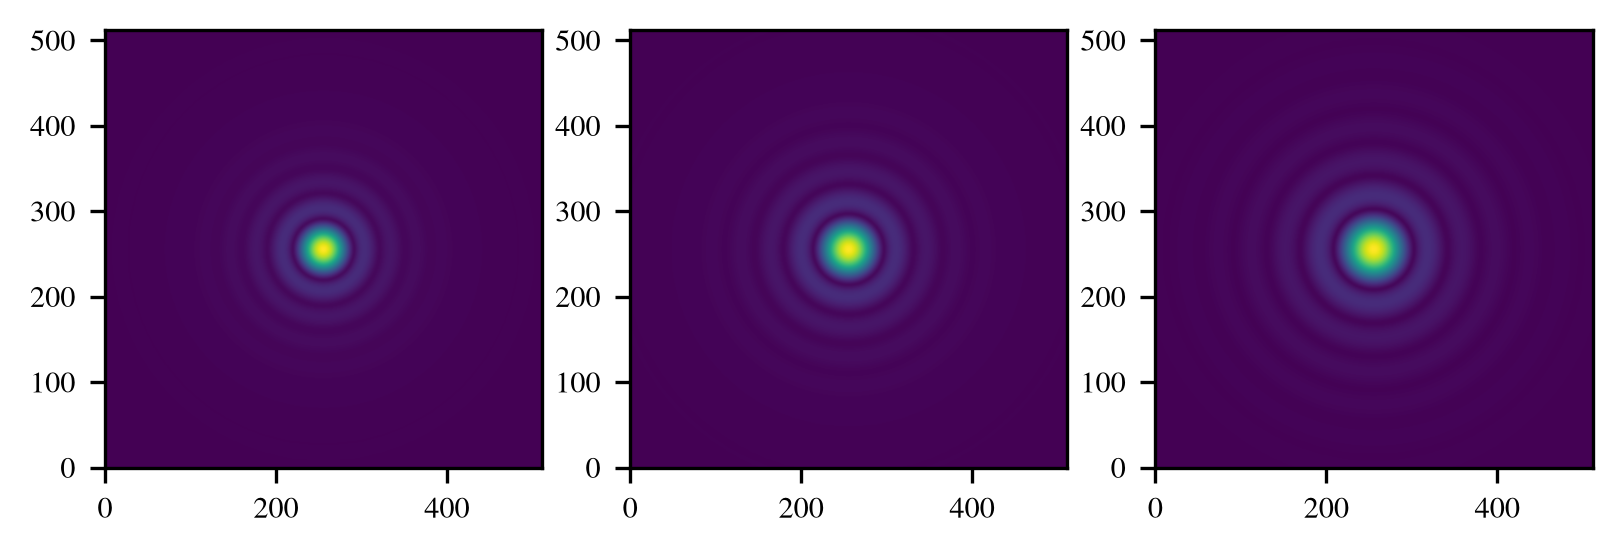

In [12]:
plt.subplot(1,3,1)
plt.imshow(psf_b**0.5)

plt.subplot(1,3,2)
plt.imshow(psf_g**0.5)

plt.subplot(1,3,3)
plt.imshow(psf_r**0.5)

In [13]:
plt.imshow(psf)

NameError: name 'psf' is not defined

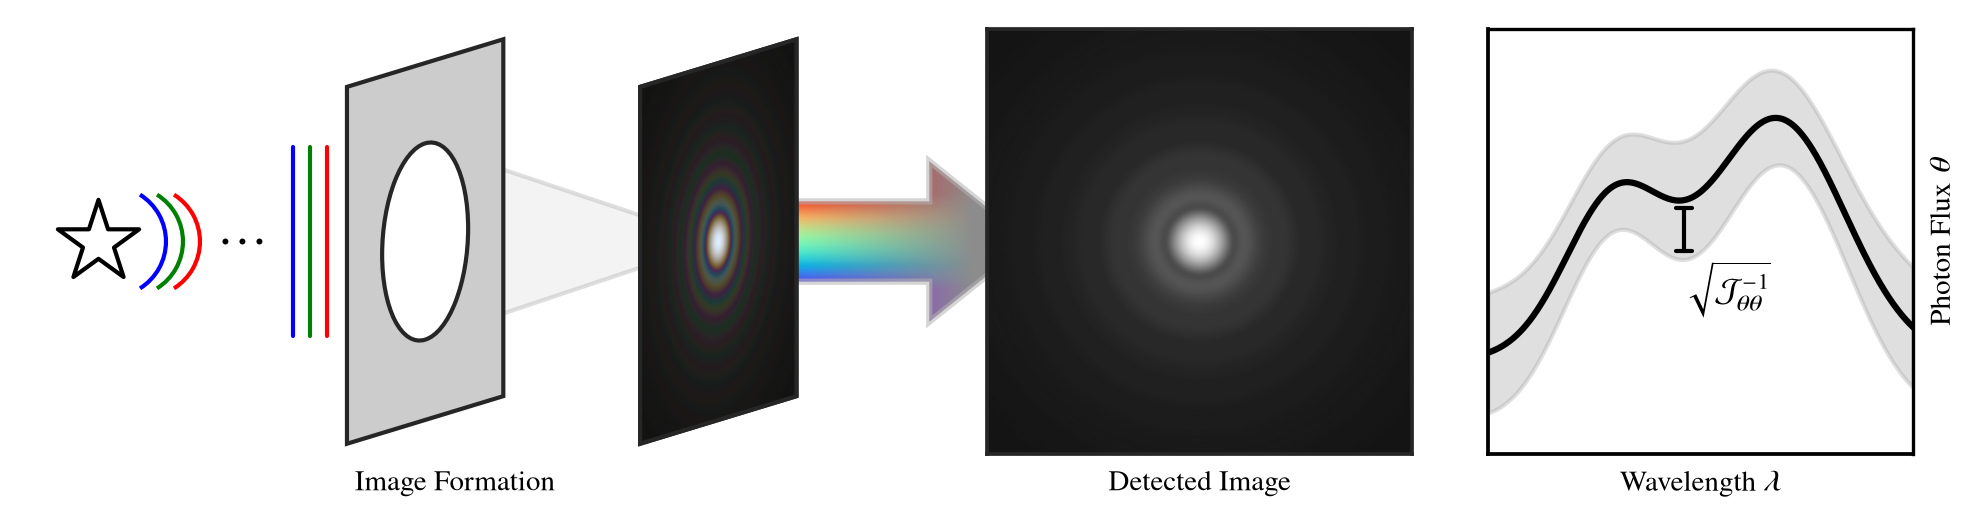

In [15]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Polygon, Circle, Arc
from matplotlib.image import BboxImage
from matplotlib.transforms import Affine2D, Bbox, TransformedBbox


# ============================================================
# FIGURE SIZE — existing style settings are preserved
# ============================================================

FIG_W = fig_width
FIG_H = fig_width / 4# + 0.1  # one row, with room for axis labels


# ============================================================
# POLYCHROMATIC PSF DISPLAY ARRAYS
# Requires existing psf_r, psf_g, psf_b arrays
# ============================================================

gamma = 0.25

poly_gray = np.asarray(psf_r + psf_g + psf_b, dtype=float)
poly_gray = poly_gray / np.nanmax(poly_gray)

rgb = np.dstack([psf_r, psf_g, psf_b]).astype(float)
rgb /= np.nanmax(rgb)
rgb = np.clip(rgb, 0, 1)
rgb_display = rgb**gamma


# ============================================================
# LAYOUT
# ============================================================

fig, axs = plt.subplots(
    1, 3,
    figsize=(FIG_W, FIG_H),
    gridspec_kw={"width_ratios": [2, 1, 1]},
    constrained_layout=True,
)

ax_opt_poly, ax_det_poly, ax_inf_poly = axs

fig.get_layout_engine().set(
    w_pad=0.01,
    h_pad=0.04,
    wspace=0.02,
)

ax_opt_poly.set_xlim(0, 10)
ax_opt_poly.set_ylim(-2.5, 2.5)
ax_opt_poly.set_box_aspect(0.5)
ax_opt_poly.set_xticks([])
ax_opt_poly.set_yticks([])

for spine in ax_opt_poly.spines.values():
    spine.set_visible(False)

for ax in [ax_det_poly, ax_inf_poly]:
    ax.set_box_aspect(1)


# ============================================================
# STYLING AND OPTICAL GEOMETRY
# ============================================================

outline = "0.15"

LW_MAIN = 1.0
LW_LIGHT = 1.0

aperture_center = np.array([4.65, 0.0])
focus_center = np.array([8.10, 0.0])

hole_radius = 0.55

plane_ex = np.array([0.92, 0.28])
plane_ey = np.array([0.00, 2.10])


def plane_transform(center, scale=1.0):
    ex = scale * plane_ex
    ey = scale * plane_ey

    return Affine2D.from_values(
        ex[0], ex[1],
        ey[0], ey[1],
        center[0], center[1],
    )


# ============================================================
# APERTURE
# ============================================================

def draw_aperture(ax, center, scale=1.0):
    T = plane_transform(center, scale=scale)

    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])

    ax.add_patch(
        Polygon(
            T.transform(square),
            closed=True,
            facecolor="0.80",
            edgecolor=outline,
            linewidth=LW_MAIN,
            zorder=5,
        )
    )

    ax.add_patch(
        Circle(
            (0, 0),
            radius=hole_radius,
            facecolor="white",
            edgecolor=outline,
            linewidth=LW_MAIN,
            transform=T + ax.transData,
            zorder=6,
        )
    )


# ============================================================
# CONVERGING CONE
# ============================================================

def draw_cone(ax, center, color, alpha=0.13):
    T = plane_transform(center)

    p_top, p_bottom = T.transform([
        [0,  hole_radius],
        [0, -hole_radius],
    ])

    ax.add_patch(
        Polygon(
            [p_top, focus_center, p_bottom],
            closed=True,
            facecolor=color,
            edgecolor="none",
            alpha=alpha,
            zorder=1,
        )
    )

    for point in [p_top, p_bottom]:
        ax.plot(
            [point[0], focus_center[0]],
            [point[1], focus_center[1]],
            color=color,
            alpha=0.35,
            linewidth=LW_LIGHT,
            zorder=2,
        )


# ============================================================
# FOCAL-PLANE SCREEN AND PSF
# ============================================================

def draw_focal_screen(ax, image, center, scale=1.0):
    T = plane_transform(center, scale=scale)

    square = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1],
    ])
    square_projected = T.transform(square)

    ax.add_patch(
        Polygon(
            square_projected,
            closed=True,
            facecolor="black",
            edgecolor=outline,
            linewidth=LW_MAIN,
            zorder=7,
        )
    )

    ax.imshow(
        image,
        extent=[-1, 1, -1, 1],
        origin="lower",
        interpolation="bilinear",
        transform=T + ax.transData,
        aspect="auto",
        zorder=8,
        clip_on=True,
    )

    ax.add_patch(
        Polygon(
            square_projected,
            closed=True,
            facecolor="none",
            edgecolor=outline,
            linewidth=LW_MAIN,
            zorder=9,
        )
    )


# ============================================================
# STAR, ARCS, DOTS AND PARALLEL RGB WAVEFRONTS
# ============================================================

def draw_star_train(ax):
    star_x = 0.80
    star_y = 0.0

    ax.scatter(
        star_x, star_y,
        marker="*",
        s=420,
        facecolor="white",
        edgecolor="black",
        linewidth=LW_MAIN,
        zorder=8,
    )

    arc_centre_x = star_x + 0.35

    for colour, offset in [
        ("blue", -0.2),
        ("green", 0.0),
        ("red", 0.2),
    ]:
        ax.add_patch(
            Arc(
                (arc_centre_x + offset, star_y),
                width=1.3,
                height=1.3,
                angle=0,
                theta1=-58,
                theta2=58,
                edgecolor=colour,
                linewidth=LW_MAIN,
                zorder=4,
            )
        )

    for xdot in [2.3, 2.5, 2.7]:
        ax.add_patch(
            Circle(
                (xdot, 0.0),
                radius=0.035,
                facecolor="black",
                edgecolor="none",
                zorder=5,
            )
        )

    hole_height = 2 * hole_radius * plane_ey[1] * 0.96

    for colour, xline in [
        ("blue", 3.1),
        ("green", 3.3),
        ("red", 3.5),
    ]:
        ax.plot(
            [xline, xline],
            [-hole_height / 2, hole_height / 2],
            color=colour,
            linewidth=LW_MAIN,
            solid_capstyle="round",
            zorder=5,
        )


# ============================================================
# DRAW OPTICAL PANEL — no panel letter
# ============================================================

draw_star_train(ax_opt_poly)

draw_cone(
    ax_opt_poly,
    center=aperture_center,
    color="0.65",
    alpha=0.13,
)

draw_aperture(
    ax_opt_poly,
    center=aperture_center,
)

draw_focal_screen(
    ax_opt_poly,
    rgb_display,
    center=focus_center,
)

ax_opt_poly.set_xlabel("Image Formation")


# ============================================================
# FACE-ON DETECTOR PSF
# ============================================================

ax_det_poly.imshow(
    poly_gray**gamma,
    origin="lower",
    cmap="gray",
    aspect="auto",
    vmin=0,
    vmax=np.max(poly_gray**gamma),
)

ax_det_poly.set_xticks([])
ax_det_poly.set_yticks([])

for spine in ax_det_poly.spines.values():
    spine.set_linewidth(0.9)
    spine.set_color(outline)

ax_det_poly.set_xlabel("Detected Image")


# ============================================================
# POLYCHROMATIC INFERENCE PANEL
# ============================================================

wave = np.linspace(0, 1, 500)

spectrum = (
    0.45
    + 0.20 * np.exp(-0.5 * ((wave - 0.30) / 0.12)**2)
    + 0.30 * np.exp(-0.5 * ((wave - 0.68) / 0.16)**2)
)

sigma_theta = 0.055 + 0.020 * np.cos(2 * np.pi * wave)**2

ax_inf_poly.plot(
    wave,
    spectrum,
    color="black",
    linewidth=1.5,
)

ax_inf_poly.fill_between(
    wave,
    spectrum - sigma_theta,
    spectrum + sigma_theta,
    color="0.65",
    alpha=0.35,
)

x_unc = 0.46
i_unc = np.argmin(np.abs(wave - x_unc))

ax_inf_poly.annotate(
    "",
    xy=(wave[i_unc], spectrum[i_unc]),
    xytext=(wave[i_unc], spectrum[i_unc] - sigma_theta[i_unc]),
    arrowprops=dict(
        arrowstyle="|-|",
        color="black",
        linewidth=1.0,
        mutation_scale=2,
    ),
)

ax_inf_poly.set_xlim(wave.min(), wave.max())

ymin = np.min(spectrum - sigma_theta)
ymax = np.max(spectrum + sigma_theta)
ypad = 0.12 * (ymax - ymin)

ax_inf_poly.set_ylim(ymin - ypad, ymax + ypad)

ax_inf_poly.set_xlabel(r"Wavelength $\lambda$")
ax_inf_poly.set_ylabel(r"Photon Flux $\theta$")
ax_inf_poly.yaxis.set_label_position("right")

ax_inf_poly.text(
    0.47, 0.45,
    r"$\sqrt{\mathcal{J}_{\theta \! \theta}^{-1}}$",
    transform=ax_inf_poly.transAxes,
    ha="left",
    va="top",
    color="k",
)

ax_inf_poly.tick_params(
    bottom=False,
    left=False,
    labelbottom=False,
    labelleft=False,
)

ax_inf_poly.spines["bottom"].set_linewidth(0.9)
ax_inf_poly.spines["left"].set_linewidth(0.9)


# ============================================================
# FINALISE AXES POSITIONS BEFORE ADDING FIGURE-LEVEL ARROW
# ============================================================

for ax in axs:
    ax.set_zorder(10)

ax_opt_poly.patch.set_alpha(0)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.98))

fig.canvas.draw()

# Freeze the resolved layout so arrow coordinates remain aligned
# when the figure is saved with a different renderer.
fig.set_layout_engine("none")


def data_to_fig(ax, x, y):
    xy_disp = ax.transData.transform((x, y))
    return fig.transFigure.inverted().transform(xy_disp)


# ============================================================
# RAINBOW-TO-GREY TRANSITION ARROW
# ============================================================

def gradient_arrow(
    fig,
    x0,
    x1,
    y,
    height,
    rgb_right=(0.55, 0.55, 0.55),
    n=400,
    grey_onset=0.10,
    grey_full=0.80,
    blue_hold=0.20,
    red_hold=0.20,
    edgecolor="0.70",
    edgealpha=0.55,
    linewidth=1.5,
):
    head = 0.05

    verts = np.array([
        [x0,        y - height / 2],
        [x1 - head, y - height / 2],
        [x1 - head, y - height],
        [x1,        y],
        [x1 - head, y + height],
        [x1 - head, y + height / 2],
        [x0,        y + height / 2],
    ])

    clip = Polygon(
        verts,
        closed=True,
        facecolor="none",
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=edgealpha,
        transform=fig.transFigure,
        zorder=2,
    )
    clip.set_in_layout(False)
    fig.add_artist(clip)

    ny = 120
    t = np.linspace(0, 1, n)
    t = np.clip(
        (t - grey_onset) / (grey_full - grey_onset),
        0,
        1,
    )[None, :, None]

    u = np.linspace(0, 1, ny)
    u_mapped = np.clip(
        (u - blue_hold) / (1 - blue_hold - red_hold),
        0,
        1,
    )

    vertical = plt.get_cmap("rainbow")(u_mapped)[:, :3]
    left = vertical[:, None, :]
    right = np.asarray(rgb_right)[None, None, :]

    image = (1 - t) * left + t * right

    bbox = TransformedBbox(
        Bbox.from_extents(x0, y - height, x1, y + height),
        fig.transFigure,
    )

    im = BboxImage(
        bbox,
        interpolation="bilinear",
        origin="lower",
        zorder=1,
    )
    im.set_data(image)
    im.set_clip_path(clip)
    im.set_in_layout(False)
    fig.add_artist(im)


x0, y_arrow = data_to_fig(
    ax_opt_poly,
    focus_center[0] + 0.45,
    0.0,
)

bbox_det = ax_det_poly.get_position()
x1 = bbox_det.x0 + 0.10 * bbox_det.width

# Preserve the original arrow's physical height despite the
# shorter single-row canvas.
arrow_height = 0.08 * (FIG_W / 2) / FIG_H

gradient_arrow(
    fig,
    x0,
    x1,
    y_arrow,
    height=arrow_height,
)


# ============================================================
# SAVE AND DISPLAY
# ============================================================

fig.savefig(
    "intro_figure_polychromatic.pdf",
    bbox_inches=None,
    facecolor="white",
    dpi=300,
    backend="pgf",
)

# Optional PNG:
# fig.savefig(
#     "intro_figure_polychromatic.png",
#     bbox_inches=None,
#     facecolor="white",
#     dpi=300,
# )

plt.show()